# Project 3 — One-dimensional finite square well

We calculate the bound-state energies and wavefunctions of a finite
square well using the shooting method and matrix diagonalization.

We use natural units with $\hbar^2/m=1$, well width $a=1$,
and exterior potential $V_0=50$.

## 1. Imports and physical parameters

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp, simpson, quad
from scipy.optimize import brentq
from scipy.linalg import eigh

# Natural units: hbar^2 / m = 1
V0 = 50.0
a = 1.0

In [ ]:
%pip install numpy scipy matplotlib

## 2. Define and plot the potential

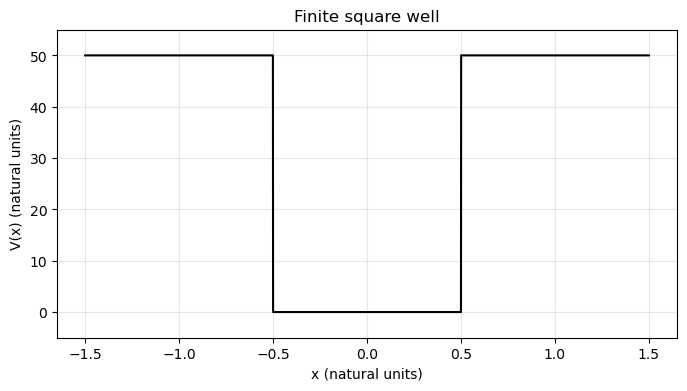

In [7]:
# Finite square well in natural units
V0 = 50.0
a = 1.0


def potential(x):
    """Zero inside the well; V0 outside."""
    return np.where(np.abs(x) <= a / 2, 0.0, V0)


# Positions used to display the potential
x_plot = np.linspace(-1.5, 1.5, 3001)

plt.figure(figsize=(8, 4))
plt.plot(x_plot, potential(x_plot), color="black")
plt.xlabel("x (natural units)")
plt.ylabel("V(x) (natural units)")
plt.title("Finite square well")
plt.ylim(-5, 55)
plt.grid(alpha=0.3)
plt.show()

# Check representative positions
assert potential(0.0) == 0.0
assert potential(0.75) == V0

## 3. Shooting method
### 3.1 Trial-energy solutions
### 3.2 Find all bound-state energies
### 3.3 Normalize wavefunctions and calculate outside probabilities
### 3.4 Check numerical convergence

E = 3.00000: even centre mismatch = -2.354555e-01
E = 3.41357: even centre mismatch = -5.980838e-07
E = 4.00000: even centre mismatch = +3.472406e-01


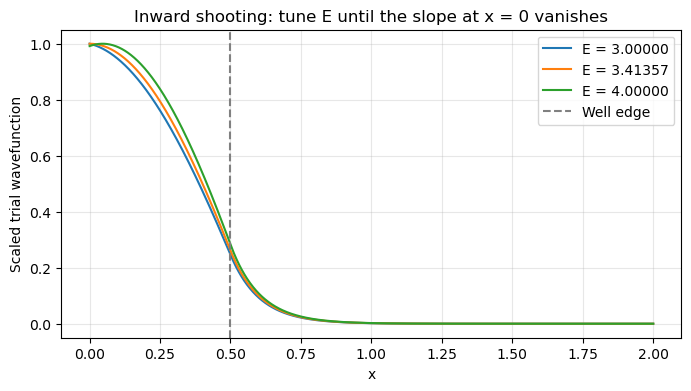


Bound-state energies (natural units)
State 1: E = 3.413570991, even
State 2: E = 13.475722739, odd
State 3: E = 29.452307586, even
State 4: E = 48.143469264, odd

State       Energy       P(|x|>a/2)     P(|x|>a)
  1       3.41357099     0.01171779     0.00000075
  2      13.47572274     0.05110807     0.00000992
  3      29.45230759     0.14007286     0.00023029
  4      48.14346926     0.49038414     0.07138413


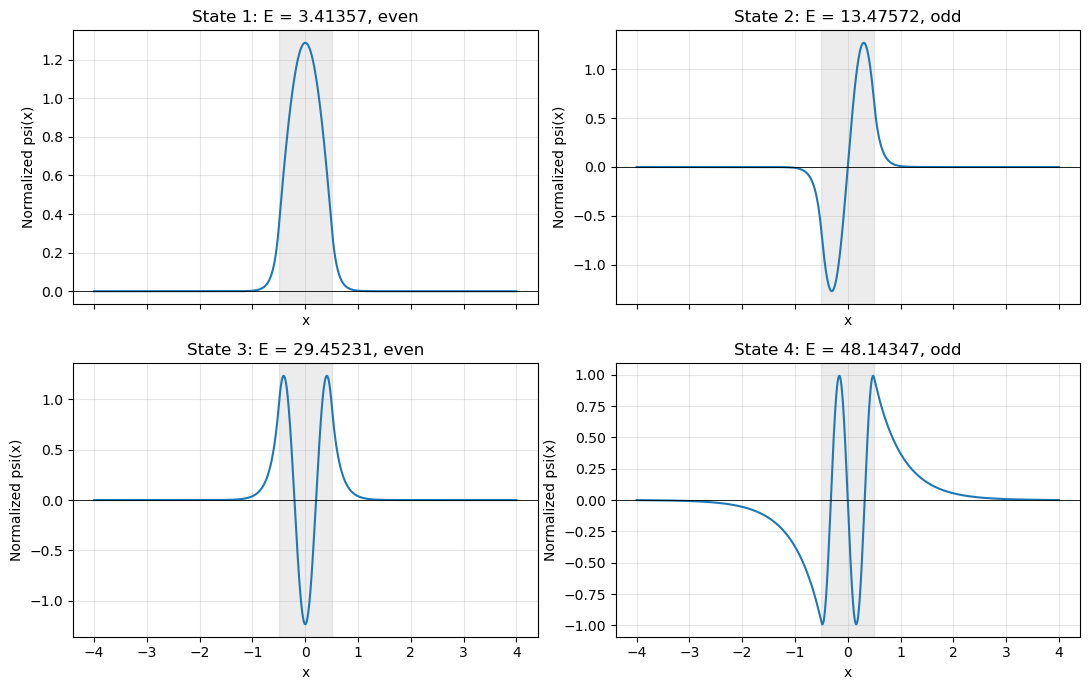


Domain convergence, compared with L=6 and rtol=1e-11
Settings             max |delta E|   max |delta P_edge|  max |delta P_a|
L = 1.5               8.380e-02        3.109e-02      3.719e-02
L = 2.5               1.642e-03        1.418e-03      2.214e-03
L = 4.0               5.048e-06        8.347e-06      1.407e-05
L = 6.0               3.032e-11        1.058e-11      2.489e-12

ODE tolerance convergence at L=6
Settings             max |delta E|   max |delta P_edge|  max |delta P_a|
rtol = 1e-06          2.246e-06        5.535e-08      9.100e-08
rtol = 1e-08          8.555e-09        3.918e-10      4.854e-10
rtol = 1e-10          3.032e-11        1.058e-11      2.489e-12
Finer energy scan     2.181e-12        3.976e-15      4.879e-18


In [8]:
# 3.1 Trial-energy solutions

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

# Uses V0 and a defined in Section 2.


def shoot_half(E, L=4.0, rtol=1e-9):
    """
    Integrate from x=L to x=0.
    Return dense solutions outside and inside the well.

    Splitting at a/2 ensures that the solver treats the
    potential discontinuity explicitly.
    """
    if L <= a / 2:
        raise ValueError("L must lie outside the well.")

    def rhs(V):
        return lambda x, y: [y[1], 2.0 * (V - E) * y[0]]

    # Arbitrary nonzero derivative sets the amplitude.
    outer = solve_ivp(
        rhs(V0), (L, a / 2), [0.0, -1.0],
        dense_output=True, rtol=rtol, atol=rtol * 1e-3,
        max_step=0.05,
    )

    if not outer.success:
        raise RuntimeError(outer.message)

    inner = solve_ivp(
        rhs(0.0), (a / 2, 0.0), outer.y[:, -1],
        dense_output=True, rtol=rtol, atol=rtol * 1e-3,
        max_step=0.05,
    )

    if not inner.success:
        raise RuntimeError(inner.message)

    return outer, inner


def centre_mismatch(E, parity, L=4.0, rtol=1e-9):
    """Zero means the required centre condition is satisfied."""
    _, inner = shoot_half(E, L, rtol)
    psi0, derivative0 = inner.y[:, -1]

    # Positive rescaling preserves zeros and improves readability.
    scale = np.hypot(psi0, derivative0)

    if parity == "even":
        return derivative0 / scale
    if parity == "odd":
        return psi0 / scale

    raise ValueError("parity must be 'even' or 'odd'.")


# Demonstrate shooting near the even ground state.
L_trial = 2.0
x_half = np.linspace(0, L_trial, 1501)

plt.figure(figsize=(8, 4))

for E in [3.0, 3.41357, 4.0]:
    outer, inner = shoot_half(E, L_trial)

    psi = np.empty_like(x_half)
    inside = x_half <= a / 2
    psi[inside] = inner.sol(x_half[inside])[0]
    psi[~inside] = outer.sol(x_half[~inside])[0]

    # Plotting scale only: these are not normalized states.
    psi /= np.max(np.abs(psi))

    plt.plot(x_half, psi, label=f"E = {E:.5f}")
    print(
        f"E = {E:.5f}: even centre mismatch = "
        f"{centre_mismatch(E, 'even', L_trial):+.6e}"
    )

plt.axvline(a / 2, color="grey", linestyle="--", label="Well edge")
plt.xlabel("x")
plt.ylabel("Scaled trial wavefunction")
plt.title("Inward shooting: tune E until the slope at x = 0 vanishes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 3.2 Find all bound-state energies
# ============================================================

def find_bound_states(L=4.0, rtol=1e-9, scan_points=201):
    """Scan 0<E<V0, then refine each sign change with Brent's method."""
    trial_E = np.linspace(1e-6, V0 - 1e-6, scan_points)
    states = []

    for parity in ["even", "odd"]:
        mismatch = [
            centre_mismatch(E, parity, L, rtol)
            for E in trial_E
        ]

        for i in range(len(trial_E) - 1):
            if mismatch[i] * mismatch[i + 1] < 0:
                energy = brentq(
                    lambda E: centre_mismatch(E, parity, L, rtol),
                    trial_E[i], trial_E[i + 1],
                    xtol=1e-11,
                )
                states.append((energy, parity))

    return sorted(states)


L = 4.0
states = find_bound_states(L=L)

print("\nBound-state energies (natural units)")
for n, (E, parity) in enumerate(states, start=1):
    print(f"State {n}: E = {E:.9f}, {parity}")

# Known state count for this particular well.
assert len(states) == 4, "Expected four states; check the scan and settings."


# ============================================================
# 3.3 Normalize wavefunctions and calculate outside probabilities
# ============================================================

def normalized_state(E, parity, L=4.0, rtol=1e-9):
    """Return psi(x), normalized over the finite interval [-L,L]."""
    outer, inner = shoot_half(E, L, rtol)

    # Rescale before integration to keep amplitudes moderate.
    amplitude = np.linalg.norm(inner.y[:, -1])

    def half_psi(r):
        if r <= a / 2:
            return inner.sol(r)[0] / amplitude
        return outer.sol(r)[0] / amplitude

    norm_squared = 2.0 * (
        quad(lambda r: half_psi(r)**2, 0, a / 2,
             epsabs=1e-11, epsrel=1e-10)[0]
        + quad(lambda r: half_psi(r)**2, a / 2, L,
               epsabs=1e-11, epsrel=1e-10)[0]
    )

    def psi(x):
        if abs(x) > L:
            raise ValueError("Evaluate psi only within [-L,L].")

        value = half_psi(abs(x)) / np.sqrt(norm_squared)
        if parity == "odd" and x < 0:
            value = -value
        return value

    return psi


def outside_probability(psi, threshold, L):
    """By symmetry, integrate one tail and multiply by two."""
    return 2.0 * quad(
        lambda x: abs(psi(x))**2, threshold, L,
        epsabs=1e-11, epsrel=1e-10,
    )[0]


results = []
x_wave = np.linspace(-L, L, 2401)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)

print("\nState       Energy       P(|x|>a/2)     P(|x|>a)")

for n, ((E, parity), ax) in enumerate(
    zip(states, axes.flat), start=1
):
    psi = normalized_state(E, parity, L)

    P_edge = outside_probability(psi, a / 2, L)
    P_a = outside_probability(psi, a, L)

    # Check normalization, splitting the integral at the well edge.
    norm_check = 2.0 * (
        quad(lambda x: psi(x)**2, 0, a / 2)[0]
        + quad(lambda x: psi(x)**2, a / 2, L)[0]
    )
    assert abs(norm_check - 1.0) < 1e-7

    results.append((E, P_edge, P_a))
    print(f"{n:3d}     {E:12.8f}   {P_edge:12.8f}   {P_a:12.8f}")

    ax.plot(x_wave, [psi(x) for x in x_wave])
    ax.axvspan(-a / 2, a / 2, color="grey", alpha=0.15)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_title(f"State {n}: E = {E:.5f}, {parity}")
    ax.set_xlabel("x")
    ax.set_ylabel("Normalized psi(x)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 3.4 Check numerical convergence
# ============================================================

def calculate_results(L, rtol=1e-9, scan_points=201):
    found = find_bound_states(L, rtol, scan_points)
    rows = []

    for E, parity in found:
        psi = normalized_state(E, parity, L, rtol)
        rows.append([
            E,
            outside_probability(psi, a / 2, L),
            outside_probability(psi, a, L),
        ])

    return np.array(rows)


# Reference settings: larger domain and tighter integration tolerance.
reference = calculate_results(L=6.0, rtol=1e-11)

def report_difference(label, values):
    if values.shape != reference.shape:
        raise RuntimeError("Different state counts: refine the energy scan.")

    differences = np.max(np.abs(values - reference), axis=0)
    print(
        f"{label:18s} "
        f"{differences[0]:12.3e} "
        f"{differences[1]:16.3e} "
        f"{differences[2]:14.3e}"
    )


print("\nDomain convergence, compared with L=6 and rtol=1e-11")
print("Settings             max |delta E|   max |delta P_edge|  max |delta P_a|")
for L_test in [1.5, 2.5, 4.0, 6.0]:
    values = calculate_results(L=L_test, rtol=1e-10)
    report_difference(f"L = {L_test}", values)

print("\nODE tolerance convergence at L=6")
print("Settings             max |delta E|   max |delta P_edge|  max |delta P_a|")
for tolerance in [1e-6, 1e-8, 1e-10]:
    values = calculate_results(L=6.0, rtol=tolerance)
    report_difference(f"rtol = {tolerance}", values)

# Check that a finer energy scan finds the same states.
finer_scan = calculate_results(L=6.0, rtol=1e-11, scan_points=401)
report_difference("Finer energy scan", finer_scan)

## 4. Matrix method
### 4.1 Define the infinite-well basis
### 4.2 Construct and diagonalize the Hamiltonian
### 4.3 Reconstruct wavefunctions and calculate outside probabilities
### 4.4 Check convergence with basis size and box width

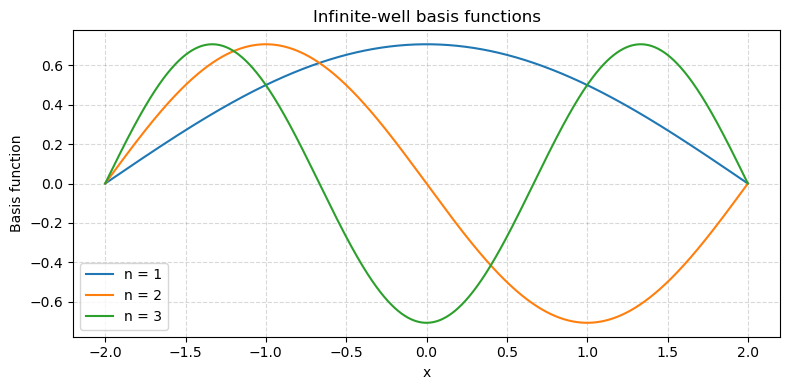

Matrix-method bound-state energies
State 1: E = 3.414448113
State 2: E = 13.478737227
State 3: E = 29.459433488
State 4: E = 48.150220829

Largest eigenvalue-equation residual: 3.016e-13

State       Energy       P(|x|>a/2)     P(|x|>a)
  1       3.41444811     0.01173977     0.00000075
  2      13.47873723     0.05118647     0.00000978
  3      29.45943349     0.14028445     0.00022975
  4      48.15022083     0.49106856     0.07169979


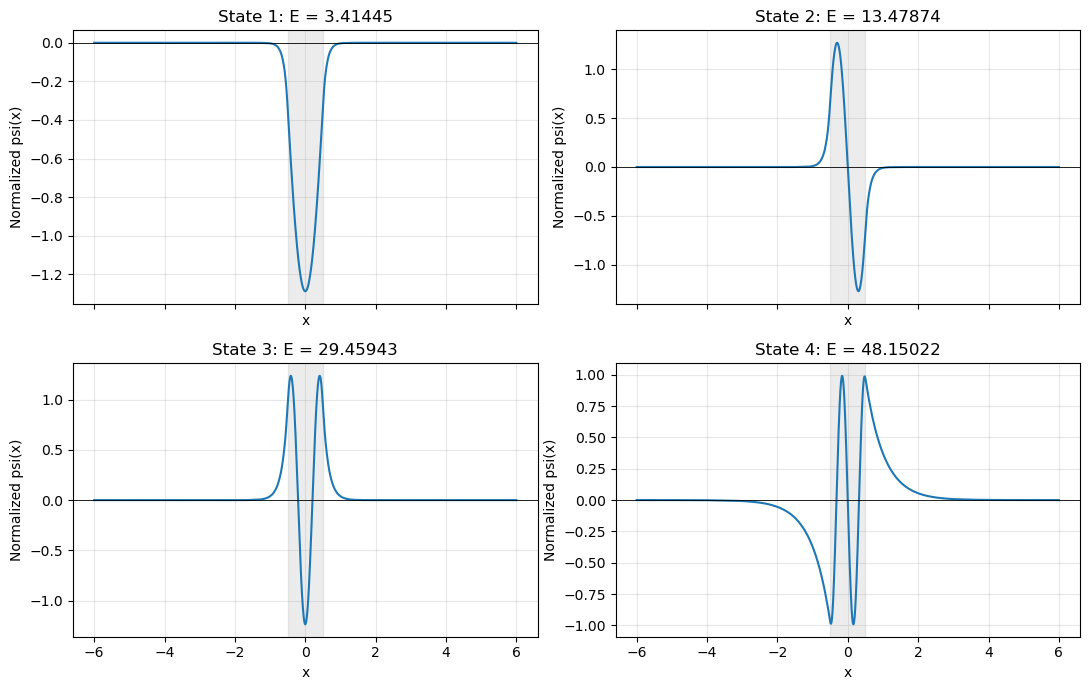


Basis convergence at b=12, relative to N=800
Settings             max |delta E|   max |delta P_edge|  max |delta P_a|
N = 50                8.770e-01        1.291e-01      7.724e-02
N = 100               5.857e-02        5.811e-03      2.537e-03
N = 200               7.021e-03        6.653e-04      2.966e-04
N = 400               7.894e-04        7.902e-05      3.544e-05

Box-width comparison, relative to b=16 and N=800
Settings             max |delta E|   max |delta P_edge|  max |delta P_a|
b=4, N=200            1.143e-02        6.958e-03      1.008e-02
b=8, N=400            3.107e-06        8.556e-06      1.416e-05
b=12, N=600           6.471e-07        7.132e-08      3.061e-08
b=16, N=800           0.000e+00        0.000e+00      0.000e+00

Matrix versus shooting on the same domain [-6,6]
Settings             max |delta E|   max |delta P_edge|  max |delta P_a|
N=800, b=12           1.078e-04        1.079e-05      4.975e-06


In [11]:
#Section 4.1: Define the infinite-well basis

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh


def basis_values(x, N, b):
    """
    Return all N basis functions evaluated at positions x.
    Rows correspond to positions; columns to basis functions.
    """
    x = np.atleast_1d(np.asarray(x, dtype=float))
    n = np.arange(1, N + 1)

    phi = np.sqrt(2.0 / b) * np.sin(
        np.pi * (x[:, None] + b / 2) * n[None, :] / b
    )

    phi[np.abs(x) > b / 2, :] = 0.0
    return phi


def interval_overlap(N, b, left, right):
    """
    Matrix with entries integral(phi_m * phi_n, left, right).
    Uses the exact sine-product integral.
    """
    if not (-b / 2 <= left < right <= b / 2):
        raise ValueError("Integration interval must lie inside the box.")

    n = np.arange(1, N + 1)
    m = n[:, None]
    n = n[None, :]

    length = right - left
    midpoint = (left + right) / 2 + b / 2

    difference = m - n
    total = m + n

    # np.sinc(z) = sin(pi*z)/(pi*z), including sinc(0)=1.
    return (length / b) * (
        np.cos(np.pi * difference * midpoint / b)
        * np.sinc(difference * length / (2 * b))
        - np.cos(np.pi * total * midpoint / b)
        * np.sinc(total * length / (2 * b))
    )


# Display the first three basis functions.
b_example = 4.0
x_basis = np.linspace(-b_example / 2, b_example / 2, 1001)
phi = basis_values(x_basis, 3, b_example)

plt.figure(figsize=(8, 4))
for j in range(3):
    plt.plot(x_basis, phi[:, j], label=f"n = {j + 1}")

plt.xlabel("x")
plt.ylabel("Basis function")
plt.title("Infinite-well basis functions")
plt.legend()
plt.grid(True, axis="both", color="gray", linestyle="--", alpha=0.6)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Orthonormality over the full box.
assert np.allclose(
    interval_overlap(10, b_example, -b_example / 2, b_example / 2),
    np.eye(10),
    atol=1e-12,
)


#Section 4.2: Construct and diagonalize the Hamiltonian

def matrix_bound_states(N, b):
    """Return bound-state energies, coefficient columns, and H."""
    if b <= a:
        raise ValueError("The computational box must be wider than the well.")

    n = np.arange(1, N + 1)
    kinetic = np.diag(n**2 * np.pi**2 / (2 * b**2))

    # V = V0 everywhere in the box, minus V0 inside the well.
    well_overlap = interval_overlap(N, b, -a / 2, a / 2)
    H = kinetic + V0 * (np.eye(N) - well_overlap)

    energies, coefficients = eigh(H)

    bound = energies < V0
    return energies[bound], coefficients[:, bound], H


N_matrix = 200
b_matrix = 12.0

E_matrix, C_matrix, H_matrix = matrix_bound_states(N_matrix, b_matrix)

print("Matrix-method bound-state energies")
for state, E in enumerate(E_matrix, start=1):
    print(f"State {state}: E = {E:.9f}")

# Check the matrix and eigenvalue equation.
assert np.allclose(H_matrix, H_matrix.T, atol=1e-12)
assert len(E_matrix) == 4

residual = H_matrix @ C_matrix - C_matrix * E_matrix[None, :]
print(f"\nLargest eigenvalue-equation residual: {np.max(np.abs(residual)):.3e}")

assert np.allclose(
    C_matrix.T @ C_matrix, np.eye(len(E_matrix)), atol=1e-10
)


#Section 4.3: Reconstruct wavefunctions and calculate outside probabilities

def matrix_probabilities(C, b):
    """
    Return outside probabilities for every coefficient column.
    Orthonormal basis + unit-length eigenvector gives unit normalization.
    """
    N = C.shape[0]

    inside_well = interval_overlap(N, b, -a / 2, a / 2)
    inside_a = interval_overlap(N, b, -a, a)

    P_edge = 1.0 - np.sum(C * (inside_well @ C), axis=0)
    P_a = 1.0 - np.sum(C * (inside_a @ C), axis=0)

    return P_edge, P_a


P_edge_matrix, P_a_matrix = matrix_probabilities(C_matrix, b_matrix)

x_matrix = np.linspace(-b_matrix / 2, b_matrix / 2, 4001)
psi_matrix = basis_values(x_matrix, N_matrix, b_matrix) @ C_matrix

print("\nState       Energy       P(|x|>a/2)     P(|x|>a)")
for j, E in enumerate(E_matrix):
    print(
        f"{j + 1:3d}     {E:12.8f}   "
        f"{P_edge_matrix[j]:12.8f}   {P_a_matrix[j]:12.8f}"
    )

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)

for j, ax in enumerate(axes.flat):
    ax.plot(x_matrix, psi_matrix[:, j])
    ax.axvspan(-a / 2, a / 2, color="grey", alpha=0.15)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_title(f"State {j + 1}: E = {E_matrix[j]:.5f}")
    ax.set_xlabel("x")
    ax.set_ylabel("Normalized psi(x)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


#Section 4.4: Check convergence with basis size and box width

def matrix_results(N, b):
    energies, coefficients, _ = matrix_bound_states(N, b)
    P_edge, P_a = matrix_probabilities(coefficients, b)
    return np.column_stack((energies, P_edge, P_a))


def print_matrix_difference(label, values, reference):
    if values.shape != reference.shape:
        raise RuntimeError("State counts differ; inspect the numerical settings.")

    difference = np.max(np.abs(values - reference), axis=0)
    print(
        f"{label:18s} {difference[0]:12.3e} "
        f"{difference[1]:16.3e} {difference[2]:14.3e}"
    )


# First vary N while keeping the box fixed.
basis_reference = matrix_results(800, 12.0)

print("\nBasis convergence at b=12, relative to N=800")
print("Settings             max |delta E|   max |delta P_edge|  max |delta P_a|")

for N_test in [50, 100, 200, 400]:
    values = matrix_results(N_test, 12.0)
    print_matrix_difference(f"N = {N_test}", values, basis_reference)


# Then vary box width, keeping N/b approximately constant.
# Both errors are present: verify basis convergence before interpreting this.
box_reference = matrix_results(800, 16.0)

print("\nBox-width comparison, relative to b=16 and N=800")
print("Settings             max |delta E|   max |delta P_edge|  max |delta P_a|")

for b_test in [4.0, 8.0, 12.0, 16.0]:
    N_test = int(50 * b_test)
    values = matrix_results(N_test, b_test)
    print_matrix_difference(
        f"b={b_test:g}, N={N_test}", values, box_reference
    )


# Compare against shooting with the same boundaries: L=b/2.
# calculate_results was defined in Section 3.4.
shooting_reference = calculate_results(L=6.0, rtol=1e-11)
matrix_comparison = matrix_results(800, 12.0)

print("\nMatrix versus shooting on the same domain [-6,6]")
print("Settings             max |delta E|   max |delta P_edge|  max |delta P_a|")
print_matrix_difference(
    "N=800, b=12", matrix_comparison, shooting_reference
)

## 5. Compare the methods and discuss results